# 02: Candidate gene markers

For each panel gene we ask three questions:

1. Is the shift larger than the general slide shift? We compare its |log2 fold change| with
   all detected genes of similar mean expression (the slide background).
2. Does the direction match published cancer-vs-benign studies? Directions and PubMed IDs are
   in `config.yaml`.
3. Is the direction robust? It must agree under library-size normalization, housekeeping
   scaling, and within epithelium-rich spots only.

Tier A meets all three, tier B two of three. Genes detected in fewer than 10% of spots in both
slides are not tiered.

There is one normal and one cancer section, from two donors, so differences between the slides
mix biology with donor, processing and depth effects (see the [README](../README.md#limitations)).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prostate_markers import io, viz

config = io.load_config()
fig_dir = io.path(config, "figures")
viz.set_style()
pd.set_option("display.precision", 3)

In [ ]:
cand = io.read_table(config, "candidate_markers.csv")
genes_all = io.read_table(config, "gene_effects_all.csv.gz", key="processed")
mk = config["markers"]
detected = genes_all[genes_all[["detect_normal", "detect_cancer"]].max(axis=1) >= mk["min_detection"]]
print(f"detected genes: {len(detected)}")
print(f"share with |log2FC| > 1 between slides: {(detected['log2fc'].abs() > 1).mean():.1%}")

detected genes: 10867
share with |log2FC| > 1 between slides: 16.2%


## Slide background

About one detected gene in six differs more than two-fold between the slides. With one section per
class, a large fold change by itself is not evidence. The plot shows where the panel genes sit in
that background.

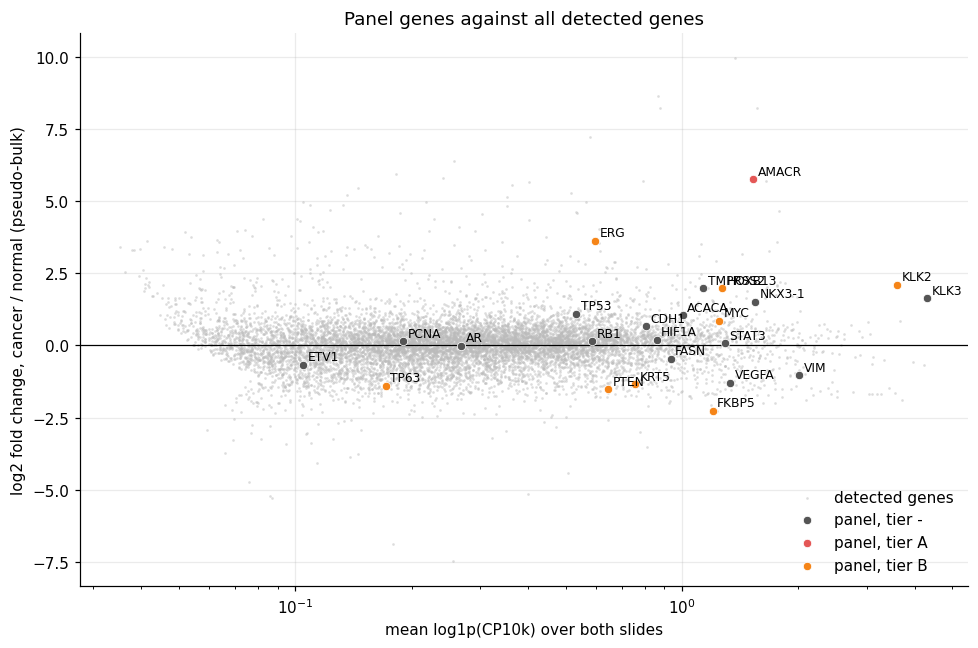

In [ ]:
tier_colors = {"A": "#E45756", "B": "#F58518", "-": "#555555"}
panel_pts = cand[cand["detected"]].merge(genes_all[["gene", "mean_log_expr"]], on="gene")
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(detected["mean_log_expr"], detected["log2fc"], s=3, color="#BBBBBB",
           alpha=0.5, linewidths=0, label="detected genes")
for tier, sub in panel_pts.groupby("tier"):
    ax.scatter(sub["mean_log_expr"], sub["log2fc"], s=30, color=tier_colors[tier],
               label=f"panel, tier {tier}", zorder=3, edgecolors="white", linewidths=0.5)
for _, r in panel_pts.iterrows():
    ax.annotate(r["gene"], (r["mean_log_expr"], r["log2fc"]), xytext=(3, 3),
                textcoords="offset points", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("mean log1p(CP10k) over both slides")
ax.set_ylabel("log2 fold change, cancer / normal (pseudo-bulk)")
ax.set_title("Panel genes against all detected genes")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
viz.save(fig, fig_dir, "02_background.png")

## Housekeeping genes as a reference

Three of the five configured housekeeping genes (GAPDH, RPLP0, PPIA) are not in the FFPE probe set,
so housekeeping scaling rests on ACTB and B2M. Both are lower in the cancer section and follow
depth closely within each slide. Scaling by them shifts every gene upward by roughly half a log2
unit, which is why it is used only as a sensitivity check.

In [ ]:
io.read_table(config, "housekeeping_check.csv")

,gene,in_probe_set,cv_cp10k_normal,rho_depth_normal,cv_cp10k_cancer,rho_depth_cancer,log2fc
0,ACTB,True,0.392,0.549,0.477,0.677,-0.56
1,GAPDH,False,NaN,NaN,NaN,NaN,NaN
2,B2M,True,0.408,0.826,0.424,0.779,-0.40
3,RPLP0,False,NaN,NaN,NaN,NaN,NaN
4,PPIA,False,NaN,NaN,NaN,NaN,NaN


## Candidate table

In [ ]:
show = ["gene", "program", "tier", "observed", "expected", "literature", "pmid", "log2fc",
        "log2fc_epithelial", "log2fc_hk", "bg_pct_log2fc", "prob_superiority",
        "detect_normal", "detect_cancer"]
cand.loc[cand["detected"], show].reset_index(drop=True)

,gene,program,tier,observed,expected,literature,pmid,log2fc,log2fc_epithelial,log2fc_hk,bg_pct_log2fc,prob_superiority,detect_normal,detect_cancer
0,AMACR,metabolism,A,up,up,concordant,1.193e+07,5.771,6.002,6.322,99.632,0.953,0.145,0.938
1,ERG,ets_fusion,B,up,context,none,1.625e+07,3.628,4.257,4.201,99.448,0.796,0.095,0.668
2,FKBP5,androgen,B,down,unknown,none,NaN,-2.256,-2.446,-1.754,96.869,0.121,0.907,0.741
3,KLK2,androgen,B,up,unknown,none,NaN,2.103,1.727,2.611,96.317,0.922,0.925,1.000
4,HOXB13,lineage,B,up,context,none,2.583e+07,1.991,1.608,2.506,95.212,0.852,0.398,0.893
5,PTEN,suppressor,B,down,down,concordant,2.188e+07,-1.519,-2.150,-1.024,93.727,0.352,0.625,0.544
6,TP63,basal,B,down,down,concordant,1.248e+07,-1.396,-3.089,-0.929,93.358,0.473,0.209,0.175
7,KRT5,basal,B,down,down,concordant,1.881e+07,-1.339,-3.131,-0.837,91.328,0.411,0.577,0.534
8,MYC,oncogene,B,up,up,concordant,1.857e+07,0.865,1.101,1.376,71.087,0.736,0.543,0.923
9,TMPRSS2,androgen,-,up,unknown,none,NaN,1.984,1.520,2.501,94.844,0.846,0.339,0.877


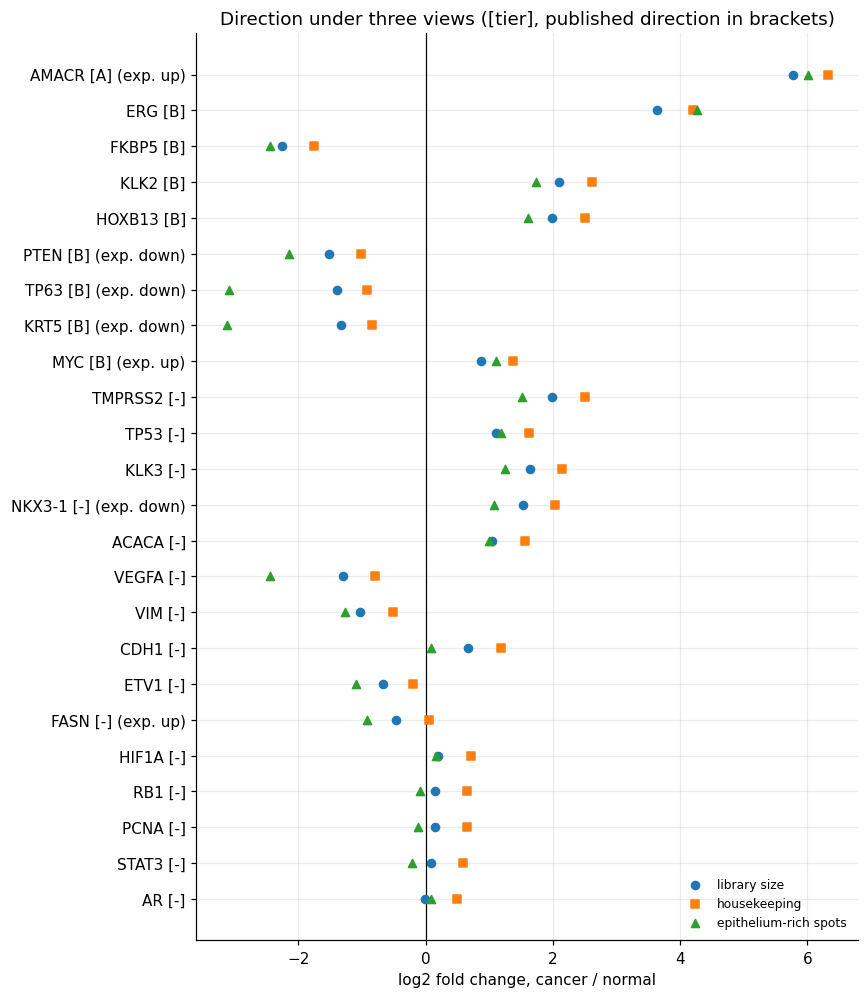

In [ ]:
plot = cand[cand["detected"]].iloc[::-1]
y = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(8, 0.32 * len(plot) + 1.5))
for col, marker, label in [("log2fc", "o", "library size"),
                           ("log2fc_hk", "s", "housekeeping"),
                           ("log2fc_epithelial", "^", "epithelium-rich spots")]:
    ax.scatter(plot[col], y, marker=marker, s=28, label=label, zorder=3)
arrow = {"up": " (exp. up)", "down": " (exp. down)"}
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y, [f"{g} [{t}]{arrow.get(e, '')}"
                  for g, t, e in zip(plot["gene"], plot["tier"], plot["expected"])])
ax.set_xlabel("log2 fold change, cancer / normal")
ax.set_title("Direction under three views ([tier], published direction in brackets)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()
viz.save(fig, fig_dir, "02_panel_directions.png")

## Reading the shortlist

- AMACR is the only tier-A marker. It is detected in most cancer-section spots and few
  normal-section spots, rises more than almost all expression-matched genes, and agrees with the
  established tissue biomarker (Rubin et al., 2002, PMID 11926890) under all three views.
- TP63 and KRT5 (basal-cell genes) are lower in the cancer section, as expected from the loss
  of the basal layer in cancer glands (PMIDs 12481011, 18813120). Within epithelium-rich spots the
  drop is about twice as large, which suggests that the drop is not only a matter of less stroma.
  They fall just short of the background threshold on the whole-slide fold change.
- PTEN decreases and MYC increases in the published direction. PTEN is close to the
  background threshold; MYC's shift is ordinary for its expression level.
- ERG is much higher in the cancer section. ERG is expected only in TMPRSS2-ERG
  fusion-positive tumors (PMID 16254181), so this is consistent with, but not evidence of, a
  fusion-positive tumor. A fusion-specific assay would be needed to say more.
- NKX3-1 goes against the published loss in cancer. Like KLK2, KLK3 and TMPRSS2 it is a luminal
  gene, and its increase shrinks within epithelium-rich spots, so composition is a likely part of
  the explanation. At this resolution we cannot tell whether NKX3-1 is lost in individual tumor
  glands.

## Set scores against random gene sets

Scores from `scanpy.tl.score_genes` for the genes expected *up* (AMACR, FASN, MYC) and *down*
(NKX3-1, PTEN, TP63, KRT5) in cancer. As a reference we draw random sets of detected genes of the
same size and measure how well their mean expression separates the slides (AUC folded around 0.5).

In [ ]:
scores = io.read_table(config, "score_effects.csv")
random_sets = io.read_table(config, "random_set_separability.csv")
scores

,feature,genes,cohens_d,prob_superiority,set_mean_separability,random_set_pct,image_link,image_link_rho
0,score_up,AMACR FASN MYC,1.759,0.887,0.916,99.8,NaN,NaN
1,score_down,NKX3-1 PTEN TP63 KRT5,0.006,0.514,0.572,37.2,gray_sd,0.304
2,logratio_KLK3_AR,NaN,1.681,0.864,NaN,NaN,NaN,NaN


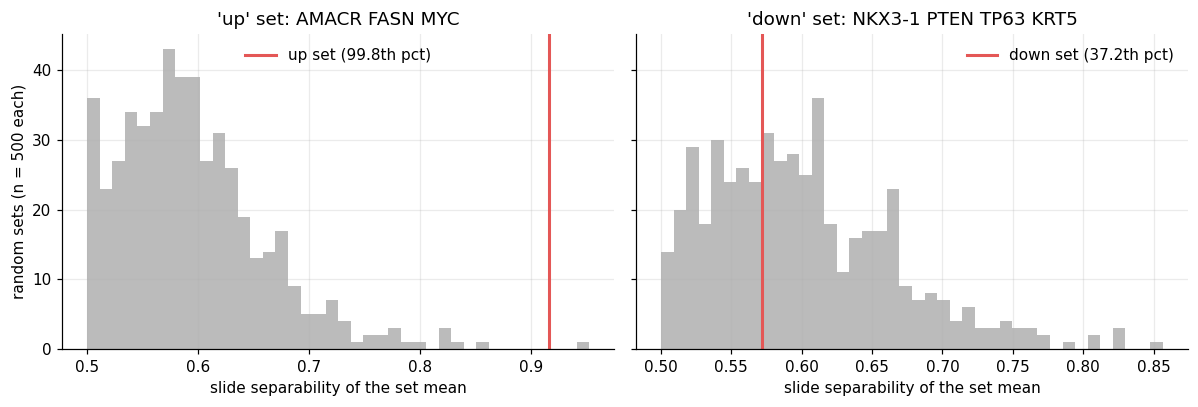

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, direction in zip(axes, ("up", "down")):
    null = random_sets.loc[random_sets["set"] == direction, "separability"]
    row = scores.set_index("feature").loc[f"score_{direction}"]
    ax.hist(null, bins=40, color="#BBBBBB")
    ax.axvline(row["set_mean_separability"], color="#E45756", lw=2,
               label=f"{direction} set ({row['random_set_pct']:.1f}th pct)")
    ax.set_xlabel("slide separability of the set mean")
    ax.set_title(f"'{direction}' set: {row['genes']}")
    ax.legend(frameon=False)
axes[0].set_ylabel(f"random sets (n = {mk['n_random_sets']} each)")
fig.tight_layout()
viz.save(fig, fig_dir, "02_set_scores_vs_random.png")

The *up* set separates the sections better than nearly all random sets of the same size. The
*down* set does not, because NKX3-1 moves the other way and cancels the basal genes. We keep the
set as configured rather than drop the gene after seeing the result.

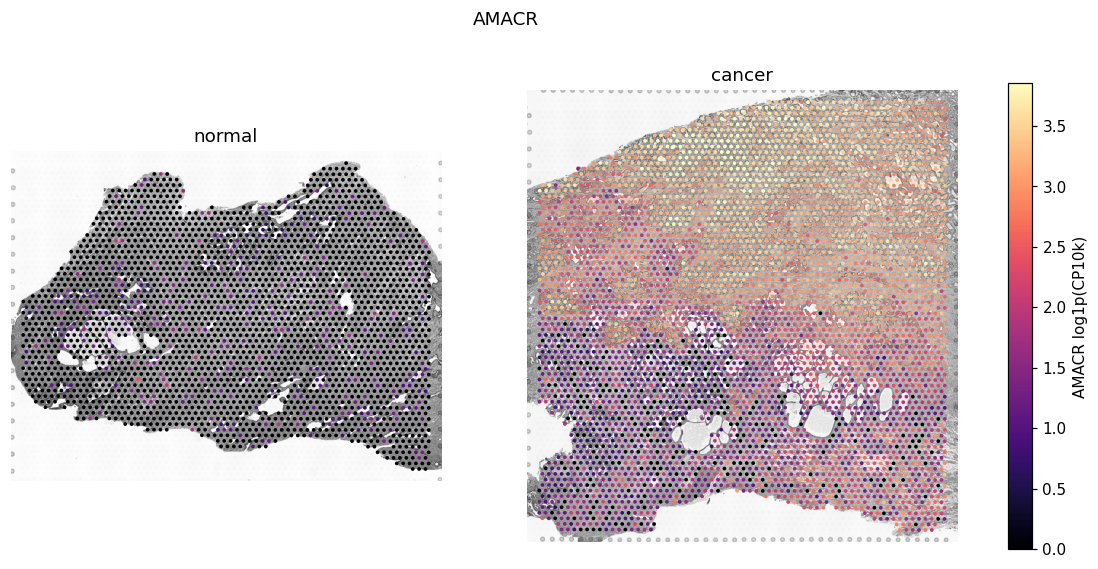

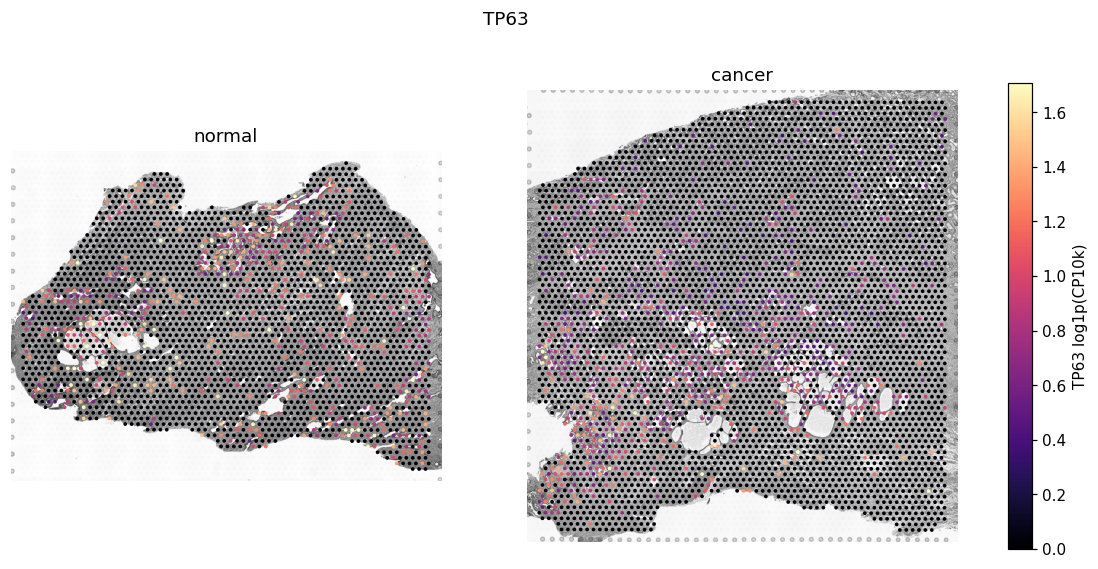

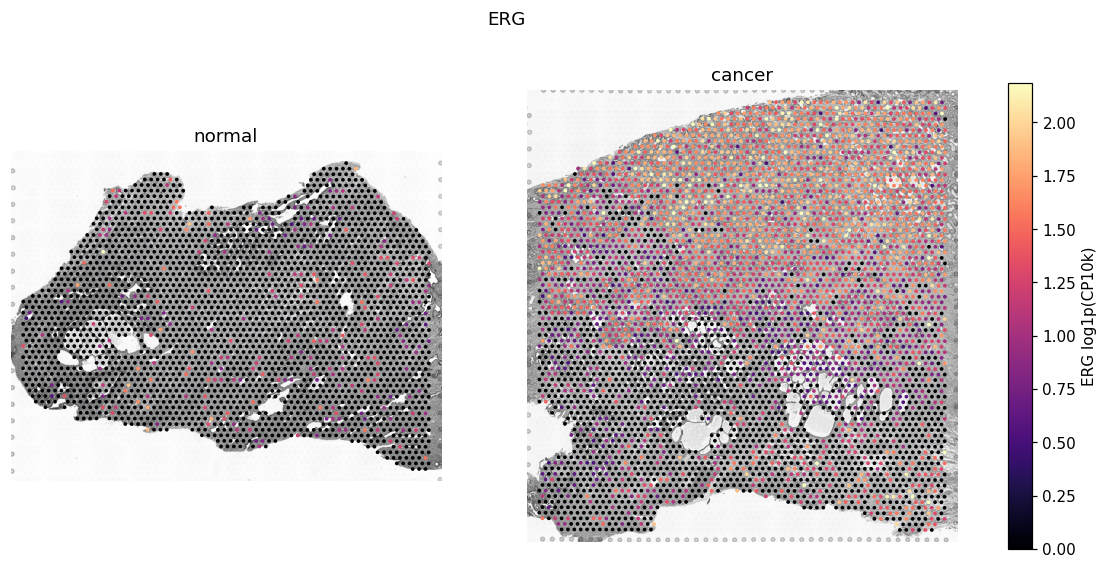

In [ ]:
slides = io.read_slides(config)
for gene in ["AMACR", "TP63", "ERG"]:
    values = {s: np.asarray(slides[s][:, gene].X.todense()).ravel() for s in io.SLIDES}
    fig = viz.paired_overlay(slides, values, f"{gene} log1p(CP10k)", cmap="magma")
    fig.suptitle(gene, y=1.0)
    viz.save(fig, fig_dir, f"02_{gene}_spatial.png")

Inside the cancer section AMACR is not uniform. It is highest in the densely cellular upper region
and lower around the large-lumen glands in the lower half, which look like benign glands. That
pattern fits a tumor area next to benign tissue, but without a pathologist's annotation of this
section it remains an observation. It is also why spot labels here mean *slide of origin*, not
*tumor*.